---
title: "Separation of Variables and Orthogonal Functions"
short_title: "E-M2 PDEs & Special Functions"
numbering:
  heading_2: true
  equation: true
---

# Separation of Variables and Orthogonal Functions

:::{tip} Where this sits in the plan
Math for **boundary-value problems** and **multipoles** (E&M topics 3 and 4). Fourier series are in mechanics M4; Taylor series in M1; eigenvectors and orthogonality in M6.

| Item | Boas | Zill | Arfken |
|---|---|---|---|
| Separation of variables for PDEs | 13 | 13, 14 | 9 |
| Legendre polynomials and spherical harmonics | 12 | 5, 14 | 15, 16 |
| Sturm–Liouville theory and orthogonal functions | 12, 13 | 12 | 8 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## Laplace's Equation

In a region with no charge, the electrostatic potential satisfies

$$
\nabla^2V = 0 .
$$ (eq-laplace)

Solutions are called **harmonic functions**, and they have a defining property: the value at any point equals the **average over any sphere** (or circle, in 2D) centered there. It follows that a harmonic function has no local maxima or minima inside the region; its extremes are on the boundary. (That is also why a charge cannot be held in stable equilibrium by electrostatic forces alone, Earnshaw's theorem.)

The averaging property also gives the simplest numerical method: put the region on a grid, fix the boundary values, and repeatedly replace each interior value with the average of its four neighbors. The values relax to the solution.

## Separation of Variables in Cartesian Coordinates

Try a product solution, $V(x, y) = X(x)\,Y(y)$. Dividing $\nabla^2V = 0$ by $XY$:

$$
\frac{X''}{X} + \frac{Y''}{Y} = 0 .
$$

The first term depends only on $x$ and the second only on $y$, so each must be a **constant**: $X''/X = -k^2$ and $Y''/Y = +k^2$. The sign choice is made so that $X$ oscillates in the direction where the boundary conditions are zero at both ends:

$$
X = \sin kx \ \text{or}\ \cos kx, \qquad Y = e^{\pm ky}\ \text{or}\ \sinh ky,\ \cosh ky .
$$

The homogeneous boundary conditions pick out a discrete set of allowed $k$ values, and a **superposition** over them matches the remaining nonzero boundary condition. Finding the coefficients is a Fourier-series problem (M4).

::::{prf:example} A rectangular box with a curved lid
:label: ex-box-lid

A long rectangular pipe, $0 < x < a$, $0 < y < b$, has three grounded walls. The top wall ($y = b$) is held at $V_0(x) = 4V_m\,x(a - x)/a^2$, a parabolic profile peaking at $V_m$. Find $V$ inside.

:::{dropdown} Solution
$V = 0$ at $x = 0$ and $x = a$ forces $X = \sin(n\pi x/a)$. $V = 0$ at $y = 0$ forces $Y = \sinh(n\pi y/a)$. So

$$
V(x, y) = \sum_{n=1}^\infty c_n\sin\frac{n\pi x}{a}\,\frac{\sinh(n\pi y/a)}{\sinh(n\pi b/a)} .
$$

At $y = b$ this must equal $V_0(x)$, so the $c_n$ are the Fourier sine coefficients of the lid profile:

$$
c_n = \frac2a\int_0^aV_0(x)\sin\frac{n\pi x}{a}\,dx = \begin{cases}\dfrac{32V_m}{n^3\pi^3} & n\text{ odd}\\[4pt] 0 & n\text{ even}\end{cases}
$$

The coefficients fall off like $1/n^3$ (the profile is smooth), so a few terms suffice.
:::
::::

In [2]:
# Fourier coefficients of the lid profile, symbolically
x, a, Vm = sp.symbols("x a V_m", positive=True)
n = sp.symbols("n", integer=True, positive=True)
cn = sp.simplify(2 / a * sp.integrate(4 * Vm * x * (a - x) / a**2 * sp.sin(n * sp.pi * x / a), (x, 0, a)))
print("c_n =", cn)

c_n = 16*V_m*(1 - (-1)**n)/(pi**3*n**3)


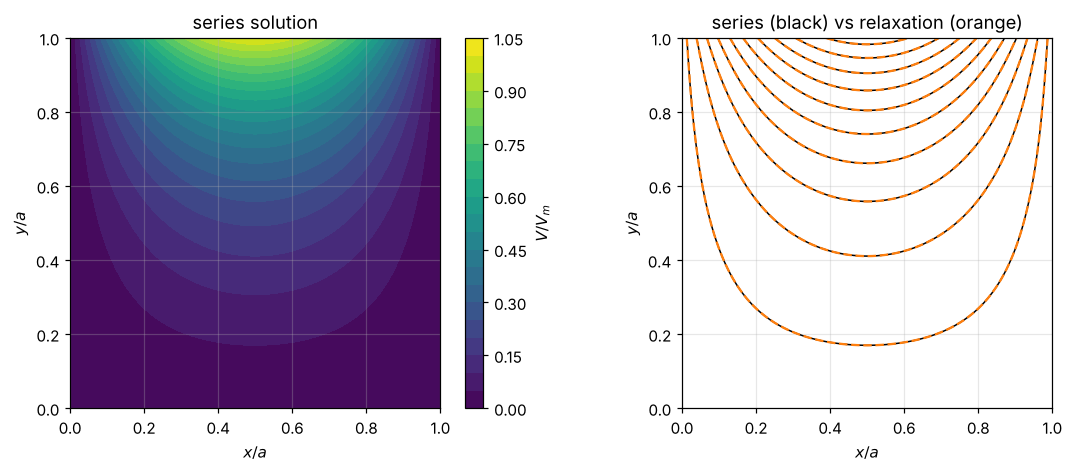

max difference series vs relaxation: 0.002


In [3]:
#| label: fig-box-lid
#| caption: Potential in the pipe from the series (left, 5 nonzero terms) and from 20 000 sweeps of neighbor-averaging relaxation (right, dashed contours on the series). The two agree; the relaxation method needs nothing but the averaging property.
a_, b_, Vm_ = 1.0, 1.0, 1.0
x = np.linspace(0, a_, 81); y = np.linspace(0, b_, 81)
X, Y = np.meshgrid(x, y)
Vs = np.zeros_like(X)
for n_ in range(1, 10, 2):
    Vs += 32 * Vm_ / (n_ * np.pi)**3 * np.sin(n_ * np.pi * X / a_) * np.sinh(n_ * np.pi * Y / a_) / np.sinh(n_ * np.pi * b_ / a_)

Vr = np.zeros_like(X)
Vr[-1, :] = 4 * Vm_ * x * (a_ - x) / a_**2
for _ in range(20000):
    Vr[1:-1, 1:-1] = 0.25 * (Vr[2:, 1:-1] + Vr[:-2, 1:-1] + Vr[1:-1, 2:] + Vr[1:-1, :-2])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
lv = np.linspace(0.05, 0.95, 10)
cs = axes[0].contourf(X, Y, Vs, levels=20, cmap="viridis"); fig.colorbar(cs, ax=axes[0], label="$V/V_m$")
axes[1].contour(X, Y, Vs, levels=lv, colors="k", linewidths=1)
axes[1].contour(X, Y, Vr, levels=lv, colors="tab:orange", linewidths=1.5, linestyles="--")
for ax in axes:
    ax.set_aspect("equal"); ax.set_xlabel("$x/a$"); ax.set_ylabel("$y/a$")
axes[0].set_title("series solution"); axes[1].set_title("series (black) vs relaxation (orange)")
plt.tight_layout(); plt.show()
print("max difference series vs relaxation:", round(float(np.max(np.abs(Vs - Vr))), 4))

### Exercises

1. Redo the example with the lid held at a constant $V_0$. Find $c_n$ and say why convergence near the top corners is slow.
2. A semi-infinite slot, $0 < y < a$, $x > 0$, has grounded sides and its end ($x = 0$) held at $V_0(y)$; $V\to0$ as $x\to\infty$. Which $X(x)$ do you choose, and why?

:::{dropdown} Hints
1. The sine coefficients of a constant on $(0, a)$ are $4V_0/(n\pi)$ for odd $n$.
2. The condition at infinity rules out one of $e^{\pm kx}$.
:::

:::{dropdown} Answers
1. $c_n = 4V_0/(n\pi)$ for odd $n$. The constant lid jumps to $0$ at the corners, so the series converges slowly there (Gibbs behavior); the coefficients fall only as $1/n$.
2. $X = e^{-n\pi x/a}$, with $Y = \sin(n\pi y/a)$; the growing exponential would blow up as $x\to\infty$.
:::

## Orthogonal Functions and Sturm–Liouville Problems

The sines in the Fourier series worked because they are **orthogonal**: $\int_0^a\sin\frac{n\pi x}{a}\sin\frac{m\pi x}{a}\,dx = 0$ for $n\ne m$. That was not luck. Every separation of variables leads to an equation of the form

$$
\frac{d}{dx}\left(p(x)\frac{dy}{dx}\right) + q(x)\,y = -\lambda\,w(x)\,y ,
$$ (eq-sturm-liouville)

a **Sturm–Liouville problem**, with boundary conditions at the ends of an interval. Its operator is the function-space analogue of a symmetric matrix (M6), and the same theorem holds:

:::{prf:theorem} Sturm–Liouville
:label: thm-sturm-liouville

The eigenvalues $\lambda_n$ are real, and eigenfunctions with different eigenvalues are orthogonal with weight $w$:

$$
\int y_n(x)\,y_m(x)\,w(x)\,dx = 0 \qquad (n\ne m) .
$$

The eigenfunctions form a **complete** set: any reasonable function on the interval can be expanded in them, with coefficients found by projection, $c_n = \int f\,y_n\,w\,dx\big/\int y_n^2\,w\,dx$.
:::

| Equation | Interval | Eigenfunctions | Weight |
|---|---|---|---|
| $y'' = -\lambda y$ | $(0, a)$, $y = 0$ at ends | $\sin(n\pi x/a)$ | $1$ |
| Legendre | $(-1, 1)$ | $P_\ell(x)$ | $1$ |
| Bessel (fixed order) | $(0, R)$ | $J_m(\alpha_{mn}s/R)$ | $s$ |
| Hermite (quantum oscillator) | $(-\infty, \infty)$ | $H_n(x)$ | $e^{-x^2}$ |

Functions are vectors, integrals with $w$ are dot products, and expanding in eigenfunctions is changing to the eigenvector basis.

## Separation in Spherical Coordinates: Legendre Polynomials

For problems with azimuthal symmetry (no $\phi$ dependence), try $V(r, \theta) = R(r)\,\Theta(\theta)$ in the spherical Laplacian. The separation constant is written $\ell(\ell + 1)$, and the two equations are

$$
\frac{d}{dr}\left(r^2\frac{dR}{dr}\right) = \ell(\ell + 1)R, \qquad
\frac{1}{\sin\theta}\frac{d}{d\theta}\left(\sin\theta\frac{d\Theta}{d\theta}\right) = -\ell(\ell + 1)\Theta .
$$

The radial equation has solutions $r^\ell$ and $r^{-(\ell+1)}$. The angular equation, with $x = \cos\theta$, is **Legendre's equation**. It has a solution that is finite at both poles only when $\ell$ is a non-negative integer, and that solution is the **Legendre polynomial** $P_\ell(\cos\theta)$, given by Rodrigues' formula

$$
P_\ell(x) = \frac{1}{2^\ell\,\ell!}\frac{d^\ell}{dx^\ell}\left(x^2 - 1\right)^\ell .
$$

So the general azimuthally symmetric solution of Laplace's equation is

$$
V(r, \theta) = \sum_{\ell=0}^\infty\left(A_\ell\,r^\ell + \frac{B_\ell}{r^{\ell+1}}\right)P_\ell(\cos\theta) .
$$ (eq-legendre-general)

Two facts make the coefficients easy to find:

$$
\int_{-1}^1P_\ell(x)P_{\ell'}(x)\,dx = \frac{2}{2\ell + 1}\,\delta_{\ell\ell'}, \qquad
\frac{1}{\sqrt{1 - 2xt + t^2}} = \sum_{\ell=0}^\infty P_\ell(x)\,t^\ell .
$$ (eq-legendre-facts)

The second is the **generating function**; with $t = r'/r$ it expands $1/|\mathbf{r} - \mathbf{r}'|$ and becomes the multipole expansion.

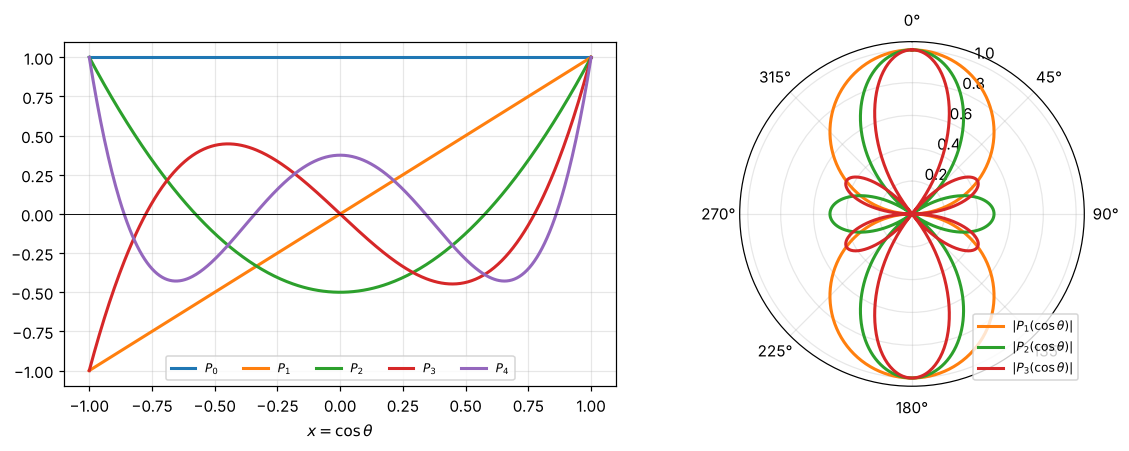

In [4]:
#| label: fig-legendre-polynomials
#| caption: The first five Legendre polynomials on −1 ≤ x ≤ 1 (left) and as functions of θ on a polar plot of |P_ℓ(cos θ)| (right, ℓ = 1, 2, 3). P_ℓ has ℓ zeros, alternating in sign like the modes of a string.
from scipy.special import eval_legendre
xx = np.linspace(-1, 1, 400)
fig = plt.figure(figsize=(11, 4.2))
ax = fig.add_subplot(1, 2, 1)
for l in range(5):
    ax.plot(xx, eval_legendre(l, xx), lw=2, label=rf"$P_{l}$")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel(r"$x = \cos\theta$"); ax.legend(ncol=5, fontsize=8, loc="lower center")
axp = fig.add_subplot(1, 2, 2, projection="polar")
th = np.linspace(0, 2 * np.pi, 600)
for l, c_ in zip([1, 2, 3], ["tab:orange", "tab:green", "tab:red"]):
    axp.plot(th, np.abs(eval_legendre(l, np.cos(th))), color=c_, lw=2, label=rf"$|P_{l}(\cos\theta)|$")
axp.set_theta_zero_location("N"); axp.set_theta_direction(-1); axp.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

In [5]:
xs = sp.symbols("x")
P = [sp.legendre(l, xs) for l in range(5)]
print("P_0..P_4:", P)
print("int P2*P3 =", sp.integrate(P[2] * P[3], (xs, -1, 1)), "| int P3^2 =", sp.integrate(P[3]**2, (xs, -1, 1)), "(2/7 expected)")
t = sp.symbols("t")
gen = sp.series(1 / sp.sqrt(1 - 2 * xs * t + t**2), t, 0, 4).removeO()
print("generating function matches:", all(sp.simplify(gen.coeff(t, l) - P[l]) == 0 for l in range(4)))

P_0..P_4: [1, x, 3*x**2/2 - 1/2, 5*x**3/2 - 3*x/2, 35*x**4/8 - 15*x**2/4 + 3/8]
int P2*P3 = 0 | int P3^2 = 2/7 (2/7 expected)
generating function matches: True


### Without azimuthal symmetry: spherical harmonics

If $V$ depends on $\phi$ too, the angular part becomes $\Theta(\theta)\,e^{im\phi}$, and the solutions are the **spherical harmonics** $Y_\ell^m(\theta, \phi)\propto P_\ell^m(\cos\theta)\,e^{im\phi}$ with $|m|\le\ell$. They are orthonormal over the sphere and are the eigenfunctions of the angular part of the Laplacian, with eigenvalue $-\ell(\ell + 1)$. They appear again, unchanged, as the angular wave functions of the hydrogen atom.

### Exercises

1. Write $x^2$ as a combination of Legendre polynomials.
2. A sphere of radius $R$ has the potential $V_0\cos^2\theta$ on its surface, with no charge inside or outside. Find $V$ inside and outside.
3. Verify that $P_2(\cos\theta)$ satisfies the angular equation with $\ell = 2$.

:::{dropdown} Hints
1. $P_2 = \tfrac12(3x^2 - 1)$.
2. Use exercise 1 and {eq}`eq-legendre-general`: inside keep $r^\ell$; outside keep $r^{-(\ell+1)}$; match at $r = R$.
3. Let sympy do it, or substitute $\Theta = \tfrac12(3\cos^2\theta - 1)$.
:::

:::{dropdown} Answers
1. $x^2 = \tfrac13P_0 + \tfrac23P_2$.
2. Inside: $V = V_0\left[\tfrac13 + \tfrac23(r/R)^2P_2(\cos\theta)\right]$. Outside: $V = V_0\left[\tfrac13\,\tfrac Rr + \tfrac23(R/r)^3P_2(\cos\theta)\right]$.
3. The left side gives $-6\,\Theta$, and $\ell(\ell + 1) = 6$.
:::

## Summary

- Laplace's equation has averaging solutions with no interior extremes; relaxation on a grid uses exactly this.
- Separating variables turns a PDE into ODEs linked by separation constants; boundary conditions select allowed values, and superposition matches the rest.
- Sturm–Liouville problems give real eigenvalues and orthogonal, complete eigenfunctions, the function-space version of diagonalizing a symmetric matrix.
- In spherical coordinates with azimuthal symmetry, $V = \sum(A_\ell r^\ell + B_\ell r^{-\ell-1})P_\ell(\cos\theta)$; orthogonality and the generating function {eq}`eq-legendre-facts` do most of the work.
- Spherical harmonics extend this to problems without azimuthal symmetry.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.